In [1]:
# ruff: noqa: F405
from pathlib import Path
from pickle import dump, load

import anndata as ad
import numpy as np
import pandas as pd
from ingest import remyelin_ds, run_nmf, run_proc_per_ds
from matplotlib import pyplot as plt
from plotnine import *  # noqa: F403

import apl
import spatialpeeler as sP
from spatialpeeler.diag import comp_sparsity, geom_point_sp, run_deg_mwu, sweep_uns

plt.rcParams["figure.dpi"] = 300
RAND_SEED = 28

In [2]:
# load dataset + run NMF
if (pth := Path("../.cache/rml.pkl")).exists():
    with open(pth, "rb") as f:
        rml = load(f)
else:
    adatas = remyelin_ds(
        Path("../data/remyelin-slideseq"),
        # load only subset of interest
        lambda obs: (
            (obs["GoodQuality"] == "Yes")
            & (
                ((obs["Timepoint"].isin([3])) & (obs["Condition"] == "LPC"))
                | (obs["Timepoint"].isin([12, 18]) & (obs["Condition"] == "Saline"))
            )
        ),
    )
    run_proc_per_ds(adatas)

    rml = ad.concat(adatas, label="puck_id", index_unique="_")
    rml.obs["puck_id_cond"] = rml.obs["puck_id"].str.cat(rml.obs["Condition"], sep="_")

    run_nmf(rml, 30, RAND_SEED)

    with open(pth, "wb") as f:
        dump(rml, f)
print(rml)

AnnData object with n_obs × n_vars = 148301 × 19512
    obs: 'Sample details', 'Animal', 'Timepoint', 'Condition', 'GoodQuality', 'puck_id', 'puck_id_cond'
    obsm: 'spatial', 'X_nmf'
    varm: 'X_nmf'
    layers: 'counts'


before proceeding with spatialPeeler, we inspect our count matrix and NMF factors to assess their sparsity

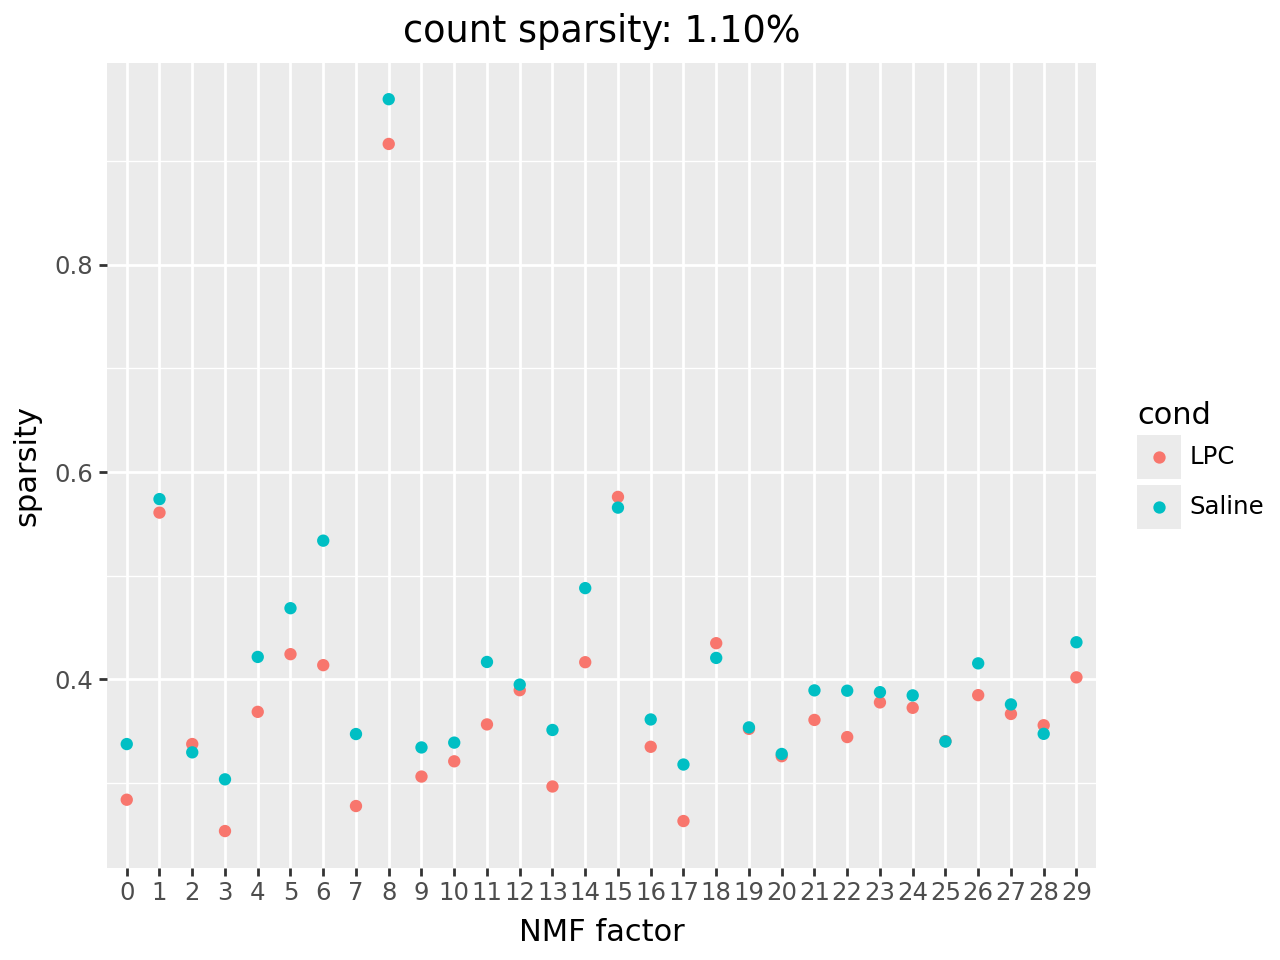

In [3]:
X_spars = rml.X.nnz / np.prod(rml.X.shape)  # ty:ignore[unresolved-attribute]
(
    comp_sparsity(rml.obsm["X_nmf"], cond=rml.obs["Condition"])
    >> ggplot()
    + aes(x="column", colour="cond", y="sparsity")
    + geom_point()
    + labs(x="NMF factor", title=f"count sparsity: {X_spars * 100:.02f}%")
).show()

we see that the dataset is overall quite sparse (only ~1% of the data is non zero)
and this is reflected in the factors, which are also mostly quite sparse

as such, we threshold our factor regression analysis to only include cells which are non-sparse for that factor

In [4]:
# run factor-wise regression step
for k in range(rml.obsm["X_nmf"].shape[1]):
    sP.run_fact_reg(
        rml,
        "Condition",
        "Saline",
        k,
        f"sP_p_hat_k={k:02}",
        X_key="X_nmf",
        filt=lambda adata: adata[adata.obsm["X_nmf"][:, k] > 0, :],
    )

print(rml)

AnnData object with n_obs × n_vars = 148301 × 19512
    obs: 'Sample details', 'Animal', 'Timepoint', 'Condition', 'GoodQuality', 'puck_id', 'puck_id_cond'
    uns: 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_hat_k=17', 'sP_p_hat_k=18', 'sP_p_hat_k=19', 'sP_p_hat_k=20', 'sP_p_hat_k=21', 'sP_p_hat_k=22', 'sP_p_hat_k=23', 'sP_p_hat_k=24', 'sP_p_hat_k=25', 'sP_p_hat_k=26', 'sP_p_hat_k=27', 'sP_p_hat_k=28', 'sP_p_hat_k=29'
    obsm: 'spatial', 'X_nmf', 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_h

we now assess our resulting regression outputs distributions \
we can extract and collate the model betas and other statistics using the sweep_uns function

/workspaces/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log


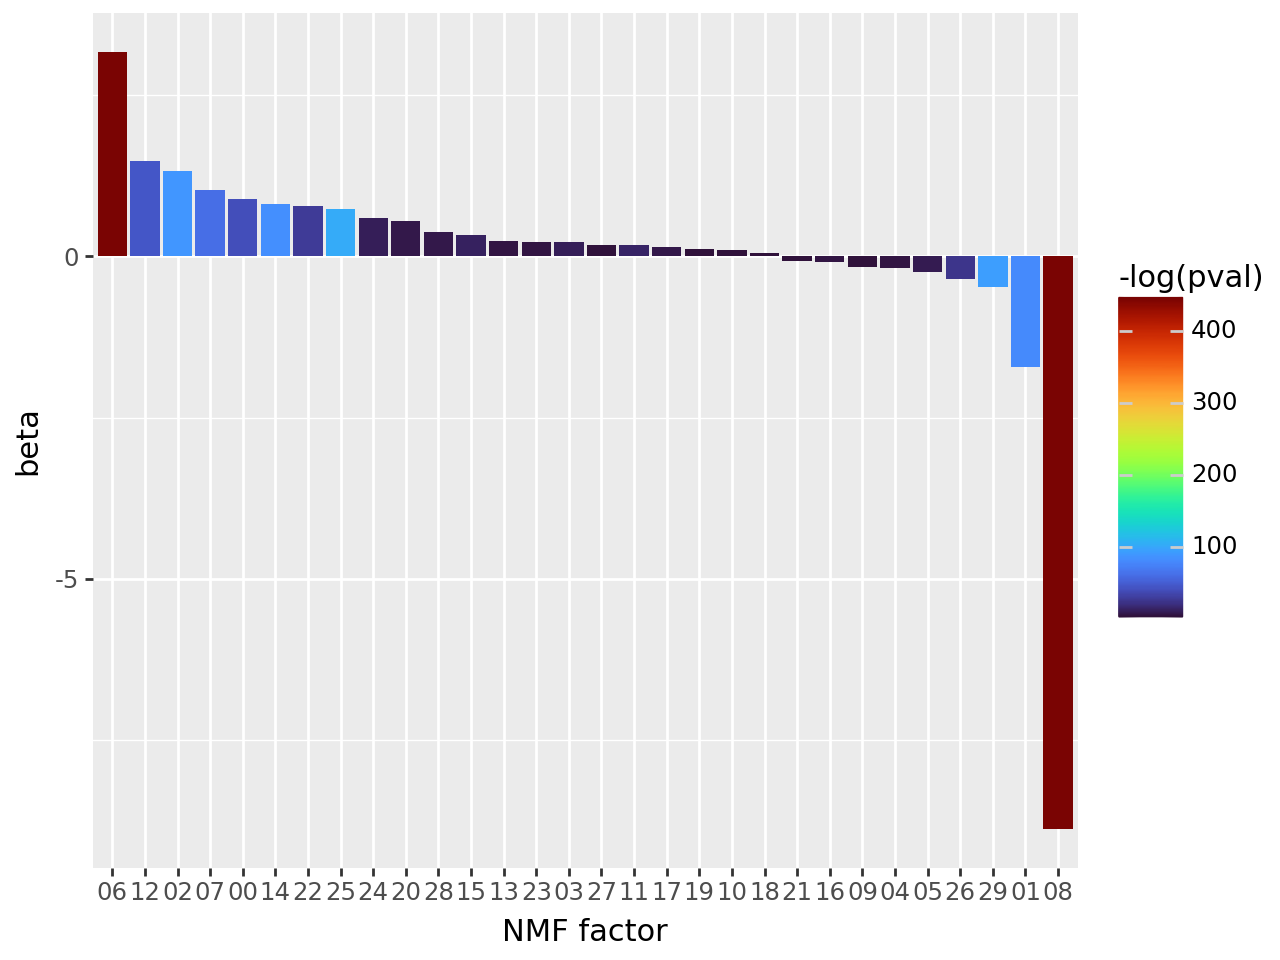

In [5]:
(
    sweep_uns(rml, "sP_p_hat_k={k}")
    >> ggplot()
    + aes(x="reorder(k, -beta)", fill="-np.log(pval)", y="beta")
    + geom_col()
    + labs(fill="-log(pval)", x="NMF factor")
    + scale_fill_cmap("turbo")
).show()

we can see that factor 6 has particularly high beta value and significance,
so we can plot the spatial distribution of the factor and the pattern

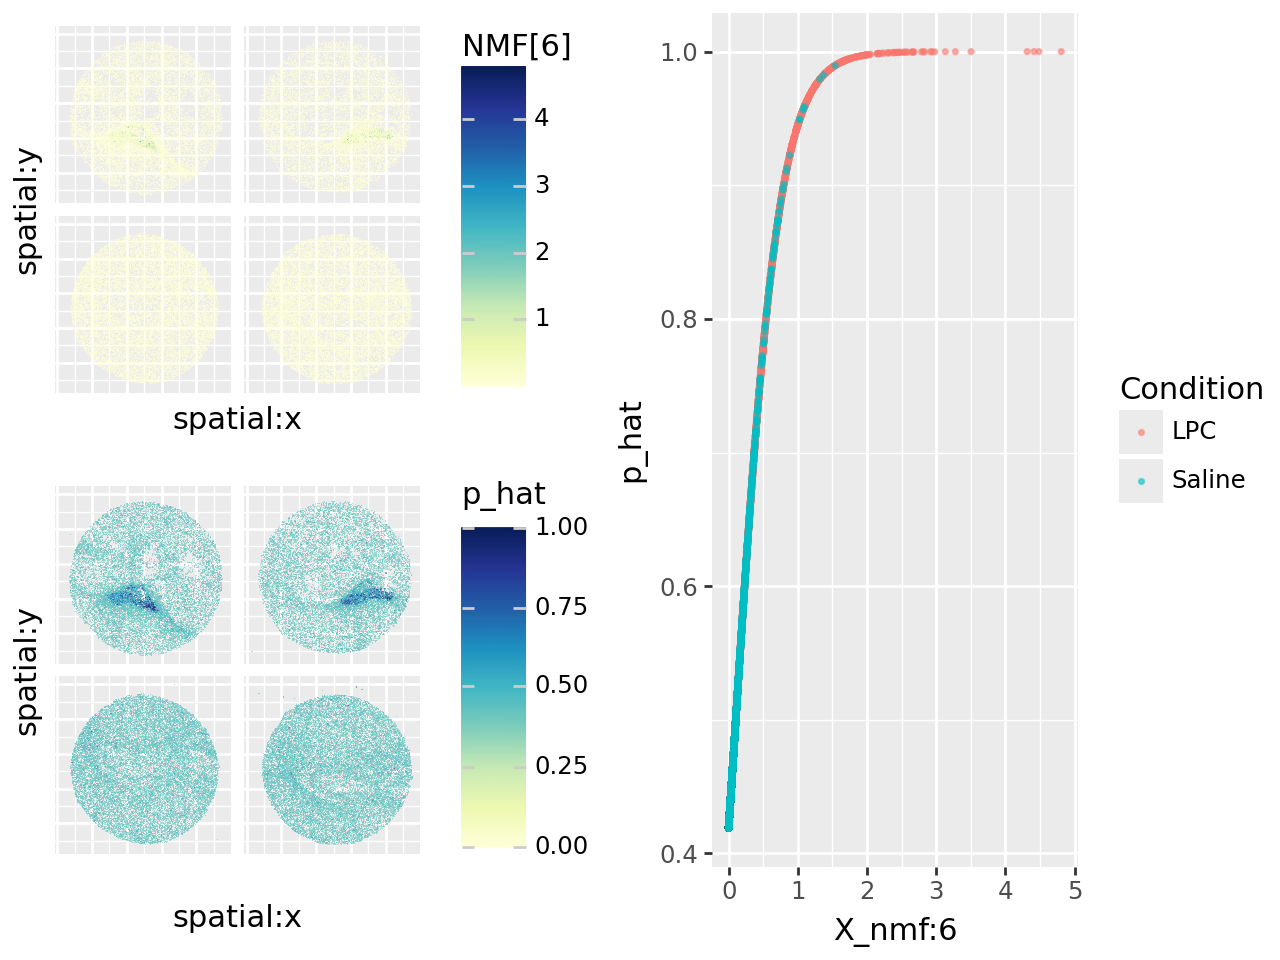

In [6]:
k_oi = 6
rml_filt = rml[rml.obsm["X_nmf"][:, k_oi] > 0, :]
obsm_sl_oi = f"sP_p_hat_k={k_oi:02}"
plo = apl.PlotAdata(rml_filt)
pl1a = plo + aes(colour=apl.obsm("X_nmf", k_oi)) + labs(colour=f"NMF[{k_oi}]") + scale_colour_cmap("YlGnBu")
pl1b = plo + aes(colour=apl.obsm(obsm_sl_oi, sP.PAT_KEY)) + labs(colour="p_hat") + scale_colour_cmap("YlGnBu", limits=(0, 1))
pl1 = (
    (pl1a / pl1b)
    & aes(x=apl.obsm("spatial", "x"), y=apl.obsm("spatial", "y"))
    & geom_point_sp(size_in_px=2, alpha=0.5)
    & facet_wrap(apl.obs("puck_id_cond"))
    & theme(
        axis_text=element_blank(),
        axis_ticks=element_blank(),
        strip_text=element_blank(),
    )
)
pl2 = (
    plo
    + aes(
        x=apl.obsm("X_nmf", k_oi),
        y=apl.obsm(obsm_sl_oi, sP.PAT_KEY),
        colour=apl.obs("Condition"),
    )
    + geom_point(alpha=0.5, shape=".")
    + labs(y="p_hat")
    + scale_colour_discrete()
)
(pl1 | pl2).show()

we can observe that the non-linearity of the logistic regression probability outputs allows
for strong extraction of the disease effect, which is not as visible with just the NMF factor on its own

we can also use the `run_deg_mwu` function provided in the `sP.diag` module to assess DEGs between various labels / combinations of labels

In [7]:
deg_conf = {
    "case_vs_control": ({apl.obs("Condition"): "LPC"},),
    #
    "case1_vs_rest": ({apl.obs("Condition"): "LPC", apl.obsm(obsm_sl_oi, sP.BIN_KEY): True},),
    "case1_vs_control": (
        {apl.obs("Condition"): "LPC", apl.obsm(obsm_sl_oi, sP.BIN_KEY): True},
        {apl.obs("Condition"): "Saline"},
    ),
    "case1_vs_case0": (
        {apl.obs("Condition"): "LPC", apl.obsm(obsm_sl_oi, sP.BIN_KEY): True},
        {apl.obs("Condition"): "LPC", apl.obsm(obsm_sl_oi, sP.BIN_KEY): False},
    ),
    "case1_vs_control0": (
        {apl.obs("Condition"): "LPC", apl.obsm(obsm_sl_oi, sP.BIN_KEY): True},
        {apl.obs("Condition"): "Saline", apl.obsm(obsm_sl_oi, sP.BIN_KEY): False},
    ),
    #
    "case0_vs_control": (
        {apl.obs("Condition"): "LPC", apl.obsm(obsm_sl_oi, sP.BIN_KEY): False},
        {apl.obs("Condition"): "Saline"},
    ),
    "case0_vs_control0": (
        {apl.obs("Condition"): "LPC", apl.obsm(obsm_sl_oi, sP.BIN_KEY): False},
        {apl.obs("Condition"): "Saline", apl.obsm(obsm_sl_oi, sP.BIN_KEY): False},
    ),
    #
    "control1_vs_control0": (
        {apl.obs("Condition"): "Saline", apl.obsm(obsm_sl_oi, sP.BIN_KEY): True},
        {apl.obs("Condition"): "Saline", apl.obsm(obsm_sl_oi, sP.BIN_KEY): False},
    ),
}

deg_results = pd.concat({k: run_deg_mwu(rml_filt, *v) for k, v in deg_conf.items()}, names=["cmp"]).reset_index(drop=False)
deg_results["cmp"] = pd.Categorical(deg_results["cmp"], categories=deg_conf.keys(), ordered=True)

we can then plot the number of DEGs generated

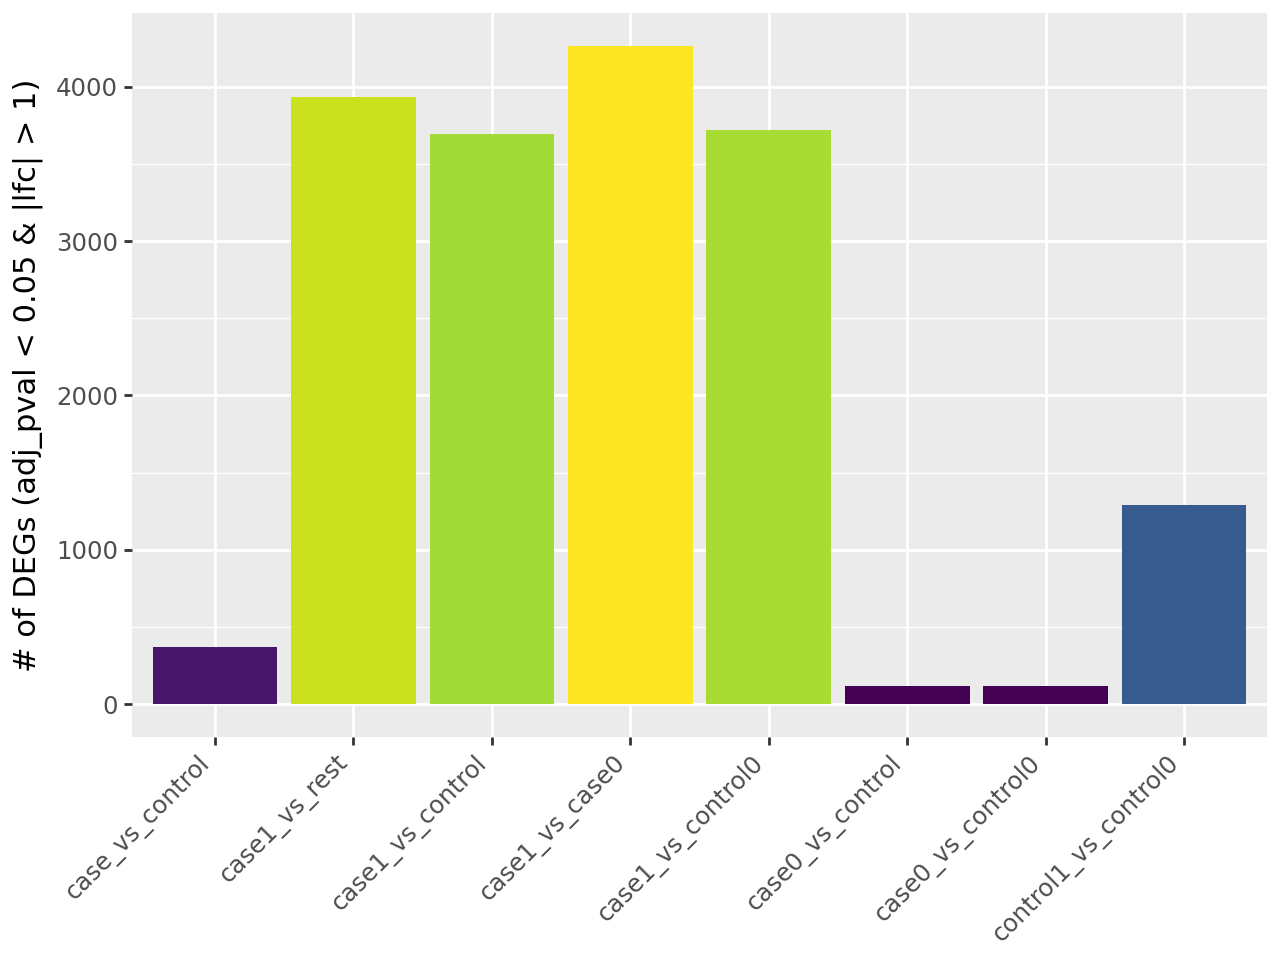

In [8]:
(
    deg_results.loc[lambda e: (e["adj_pval"] < 0.05) & (e["lfc"].abs() > 1)]
    .groupby("cmp", observed=True)["gene"]
    .count()
    .reset_index(drop=False)
    >> ggplot()
    + aes(x="cmp", y="gene", fill=after_stat("y"))
    + geom_col()
    + theme(axis_text_x=element_text(angle=45, hjust=1))
    + guides(fill="none")
    + labs(x="", y="# of DEGs (adj_pval < 0.05 & |lfc| > 1)")
).show()

we can also assess the distributions of p_hat values across the binarized labels:

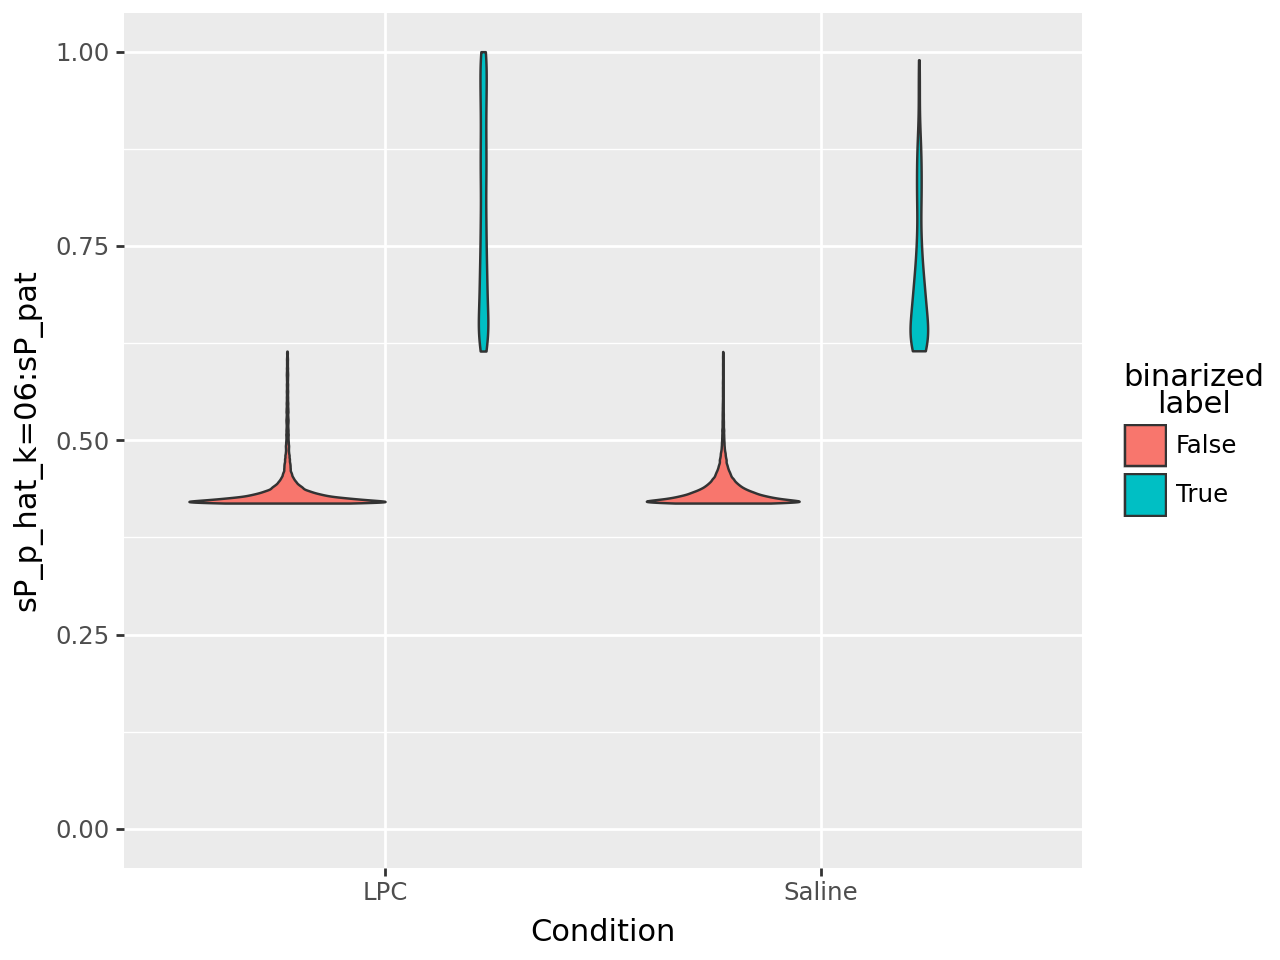

In [9]:
(
    plo
    + aes(
        x=apl.obs("Condition"),
        y=apl.obsm(obsm_sl_oi, sP.PAT_KEY),
        fill=apl.obsm(obsm_sl_oi, sP.BIN_KEY),
    )
    + geom_violin()
    + labs(fill="binarized\nlabel")
    + lims(y=(0, 1))
).show()

given factor 6 displays interesting properties, we proceed with gene-wise analysis for factor 6

/workspaces/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log


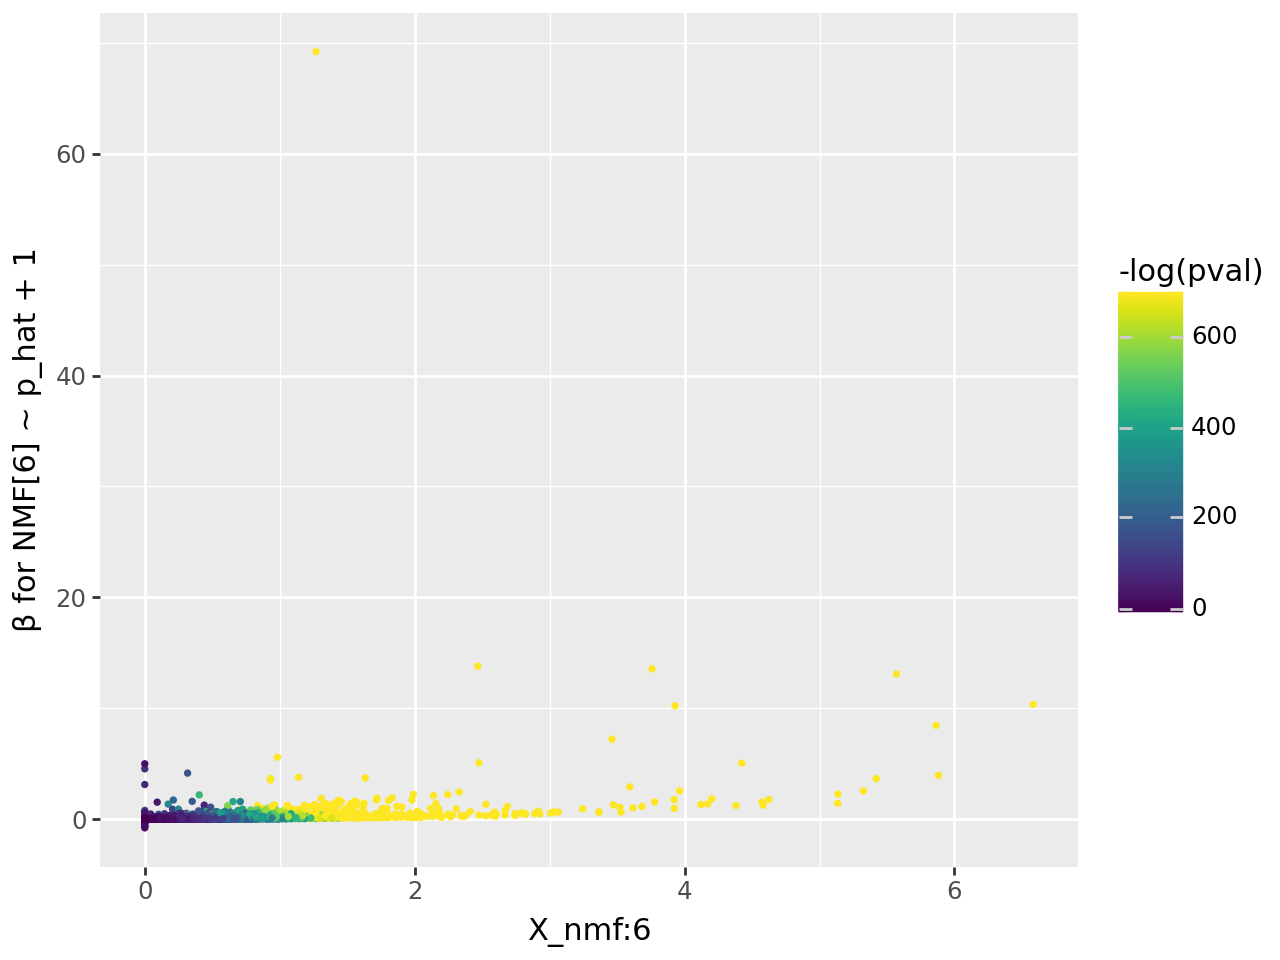

In [10]:
sP.run_gene_reg(rml, f"sP_p_hat_k={k_oi:02}", f"sp_gene_id_k={k_oi:02}", layer="counts")

(
    apl.PlotAdata(rml)
    + aes(
        x=apl.varm("X_nmf", k_oi),
        y=apl.varm("sp_gene_id_k=06", "reg_beta"),
        colour=stage(apl.varm("sp_gene_id_k=06", "reg_pval"), "-np.log(color)"),
    )
    + geom_point(size=1.5, shape="o", stroke=0)
    + labs(colour="-log(pval)", y=f"β for NMF[{k_oi}] ~ p_hat + 1")
).show()